# ДЗ 8. Сравнение моделей
Сравним семь семейств моделей, масштабирование и балансировку классов по влиянию на качество предсказания ухода сотрудника.
Уход - отсутствие педагога в следующем годовом срезе, переход между школами уходом не считаем.
Читаем `HW/data/data_clean.parquet`.

In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'dashboard/app.py').is_file():
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data'
HW_DATA_DIR = ROOT / 'HW/data'

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

root = Path.cwd()
if not (root / 'dashboard/app.py').is_file():
    root = root.parent
df = pd.read_parquet(ROOT / 'HW/data/data_clean.parquet')

def with_imputer(estimator):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('model', estimator)])

## 1. Данные
В исходной таблице несколько предметных строк на педагога. Оставим одну строку на `id, year`.
Возьмём те же признаки, что раньше: возраст, стаж, нагрузку и основные категории. Противоречивый стаж оставлен неизвестным. Медианы для моделей, требующих заполнения, обучаются внутри Pipeline; деревья и лес поддерживают NaN напрямую.
Исход 2024 неизвестен, поэтому для моделей используем только 2022 и 2023.

In [2]:
numeric = [
    'age', 'experience_age_pedagogic_clean', 'experience_age_other_clean',
    'n_unique_subjects', 'n_unique_parallel', 'min_parallel', 'max_parallel',
]
binary = ['sex', 'class_manager']
categorical = ['main_position_cat', 'academic_degree_cat', 'category_qual_cat']
features = numeric + binary + categorical

df = df.drop_duplicates(['id', 'year'])
df = df.rename(columns={'target': 'is_out_next_year'})
display(df.groupby('year')['is_out_next_year'].agg(['size', 'count', 'sum']))

train = df[df['year'] == 2022]
test = df[df['year'] == 2023]
X_train = train[features]
y_train = train['is_out_next_year'].astype(int)
X_test = test[features]
y_test = test['is_out_next_year'].astype(int)

X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42,
)
print('Обучение:', len(X_fit), 'Проверка:', len(X_valid), 'Тест:', len(X_test))

,size,count,sum
year,,,
2022,17396,17396,2596.0
2023,17394,17394,2299.0
2024,17933,0,0.0


Обучение: 13916 Проверка: 3480 Тест: 17394


## 2. Кодирование и масштабирование
Категории превратим в столбцы 0/1 через `get_dummies`. Набор столбцов берём из обучающей части.
Для выбора настроек используем 80% 2022 года и проверяем на оставшихся 20% (validation).
Масштабируем только числовые признаки; бинарные и созданные столбцы 0/1 оставляем как есть.

In [3]:
X_fit = pd.get_dummies(X_fit, columns=categorical).astype(float)
X_valid = pd.get_dummies(X_valid, columns=categorical).astype(float)
X_valid = X_valid.reindex(columns=X_fit.columns, fill_value=0)

fit_data = {'none': X_fit}
valid_data = {'none': X_valid}

for name, scaler in [('standard', StandardScaler()), ('robust', RobustScaler())]:
    fit_data[name] = X_fit.copy()
    valid_data[name] = X_valid.copy()
    fit_data[name][numeric] = scaler.fit_transform(X_fit[numeric])
    valid_data[name][numeric] = scaler.transform(X_valid[numeric])

# Сюда будем добавлять лучшие результаты проверки каждой модели.
validation = []

## 3. KNN
Сравним 5 и 15 соседей с разным масштабированием.
Настройки выбираем по balanced accuracy: она учитывает оба класса.

In [4]:
knn_results = []
for scaling in ['none', 'standard', 'robust']:
    for k in [5, 15]:
        knn = with_imputer(KNeighborsClassifier(n_neighbors=k))
        knn.fit(fit_data[scaling], y_fit)
        pred = knn.predict(valid_data[scaling])
        knn_results.append([k, scaling, accuracy_score(y_valid, pred),
                            balanced_accuracy_score(y_valid, pred)])

knn_table = pd.DataFrame(knn_results, columns=['k', 'scaling', 'accuracy', 'balanced_accuracy'])
display(knn_table)
best_knn = knn_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
knn_k = int(best_knn['k'])
knn_scaling = best_knn['scaling']
validation.append(['KNN', knn_scaling, 'none', best_knn['accuracy'], best_knn['balanced_accuracy']])

,k,scaling,accuracy,balanced_accuracy
0,5,none,0.839943,0.534899
1,15,none,0.848563,0.504211
2,5,standard,0.834483,0.530896
3,15,standard,0.848851,0.508352
4,5,robust,0.834770,0.525503
5,15,robust,0.849138,0.509316


## 4. Дерево решений
Сравним глубины 3, 7 и 12. Для дерева масштабирование не требуется.

In [5]:
tree_results = []
for depth in [3, 7, 12]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=10, random_state=42)
    tree.fit(X_fit, y_fit)
    pred = tree.predict(X_valid)
    tree_results.append([depth, accuracy_score(y_valid, pred), balanced_accuracy_score(y_valid, pred)])

tree_table = pd.DataFrame(tree_results, columns=['depth', 'accuracy', 'balanced_accuracy'])
display(tree_table)
best_tree = tree_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
tree_depth = int(best_tree['depth'])
validation.append(['Decision Tree', 'none', 'none', best_tree['accuracy'], best_tree['balanced_accuracy']])

,depth,accuracy,balanced_accuracy
0,3,0.852299,0.510379
1,7,0.847989,0.514202
2,12,0.831897,0.524609


## 5. Логистическая регрессия
Сравним два значения C и три варианта масштабирования. C задаёт силу ограничения коэффициентов.

In [6]:
lr_results = []
for scaling in ['none', 'standard', 'robust']:
    for c in [0.1, 1.0]:
        lr = with_imputer(LogisticRegression(C=c, max_iter=3000, random_state=42))
        lr.fit(fit_data[scaling], y_fit)
        pred = lr.predict(valid_data[scaling])
        lr_results.append([c, scaling, accuracy_score(y_valid, pred),
                           balanced_accuracy_score(y_valid, pred)])

lr_table = pd.DataFrame(lr_results, columns=['C', 'scaling', 'accuracy', 'balanced_accuracy'])
display(lr_table)
best_lr = lr_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
lr_c = float(best_lr['C'])
lr_scaling = best_lr['scaling']
validation.append(['Logistic Regression', lr_scaling, 'none', best_lr['accuracy'], best_lr['balanced_accuracy']])

,C,scaling,accuracy,balanced_accuracy
0,0.1,none,0.851724,0.504479
1,1.0,none,0.852586,0.507369
2,0.1,standard,0.851724,0.504479
3,1.0,standard,0.852299,0.507201
4,0.1,robust,0.851724,0.504479
5,1.0,robust,0.852586,0.507369


## 6. SVM
Используем линейную SVM, чтобы обучение было быстрым. Сравним C и масштабирование.

In [7]:
svm_results = []
for scaling in ['none', 'standard', 'robust']:
    for c in [0.1, 1.0]:
        svm = with_imputer(LinearSVC(C=c, dual='auto', max_iter=10000, random_state=42))
        svm.fit(fit_data[scaling], y_fit)
        pred = svm.predict(valid_data[scaling])
        svm_results.append([c, scaling, accuracy_score(y_valid, pred),
                            balanced_accuracy_score(y_valid, pred)])

svm_table = pd.DataFrame(svm_results, columns=['C', 'scaling', 'accuracy', 'balanced_accuracy'])
display(svm_table)
best_svm = svm_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
svm_c = float(best_svm['C'])
svm_scaling = best_svm['scaling']
validation.append(['SVM', svm_scaling, 'none', best_svm['accuracy'], best_svm['balanced_accuracy']])

,C,scaling,accuracy,balanced_accuracy
0,0.1,none,0.851437,0.502721
1,1.0,none,0.851437,0.502721
2,0.1,standard,0.851724,0.502890
3,1.0,standard,0.851724,0.502890
4,0.1,robust,0.851724,0.502890
5,1.0,robust,0.851724,0.502890


## 7. Random Forest
Сравним лес из 50 и 100 деревьев. Масштабирование не используем.

In [8]:
forest_results = []
for n in [50, 100]:
    forest = RandomForestClassifier(n_estimators=n, max_depth=10, min_samples_leaf=5, random_state=42)
    forest.fit(X_fit, y_fit)
    pred = forest.predict(X_valid)
    forest_results.append([n, accuracy_score(y_valid, pred), balanced_accuracy_score(y_valid, pred)])

forest_table = pd.DataFrame(forest_results, columns=['trees', 'accuracy', 'balanced_accuracy'])
display(forest_table)
best_forest = forest_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
forest_n = int(best_forest['trees'])
validation.append(['Random Forest', 'none', 'none', best_forest['accuracy'], best_forest['balanced_accuracy']])

,trees,accuracy,balanced_accuracy
0,50,0.852011,0.506237
1,100,0.852299,0.506406


## 8. AdaBoost
Сравним 50 и 100 деревьев в бустинге.

In [9]:
ada_results = []
for n in [50, 100]:
    ada = with_imputer(AdaBoostClassifier(n_estimators=n, learning_rate=0.5, random_state=42))
    ada.fit(X_fit, y_fit)
    pred = ada.predict(X_valid)
    ada_results.append([n, accuracy_score(y_valid, pred), balanced_accuracy_score(y_valid, pred)])

ada_table = pd.DataFrame(ada_results, columns=['trees', 'accuracy', 'balanced_accuracy'])
display(ada_table)
best_ada = ada_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
ada_n = int(best_ada['trees'])
validation.append(['AdaBoost', 'none', 'none', best_ada['accuracy'], best_ada['balanced_accuracy']])

,trees,accuracy,balanced_accuracy
0,50,0.851149,0.500963
1,100,0.851724,0.502890


## 9. Стекинг
Объединим логистическую регрессию и дерево. Итоговая модель учится на прогнозах трёх внутренних частей.
Scaler оставляем внутри логистической регрессии, чтобы он обучался отдельно в каждой части.

In [10]:
stack_lr = Pipeline([
    ('scale', ColumnTransformer([('num', with_imputer(StandardScaler()), numeric)], remainder='passthrough')),
    ('model', LogisticRegression(max_iter=3000, random_state=42)),
])
stacking = StackingClassifier(
    estimators=[
        ('lr', stack_lr),
        ('tree', DecisionTreeClassifier(max_depth=7, min_samples_leaf=10, random_state=42)),
    ],
    final_estimator=LogisticRegression(max_iter=3000, random_state=42),
    cv=3,
)
stacking.fit(X_fit, y_fit)
pred = stacking.predict(X_valid)
acc = accuracy_score(y_valid, pred)
bacc = balanced_accuracy_score(y_valid, pred)
print('Accuracy:', acc, 'Balanced accuracy:', bacc)
validation.append(['Stacking', 'inside model', 'none', acc, bacc])

validation_table = pd.DataFrame(validation, columns=[
    'algorithm', 'scaling', 'balancing', 'accuracy', 'balanced_accuracy',
])
display(validation_table.sort_values('balanced_accuracy', ascending=False))

Accuracy: 0.8511494252873564 Balanced accuracy: 0.5097032130607336


,algorithm,scaling,balancing,accuracy,balanced_accuracy
0,KNN,none,none,0.839943,0.534899
1,Decision Tree,none,none,0.831897,0.524609
6,Stacking,inside model,none,0.851149,0.509703
2,Logistic Regression,none,none,0.852586,0.507369
4,Random Forest,none,none,0.852299,0.506406
3,SVM,standard,none,0.851724,0.502890
5,AdaBoost,none,none,0.851724,0.502890


## 10. Масштабирование
Покажем лучший результат каждого варианта на validation. Параметры подбирались отдельно для каждого варианта.

scaling,none,robust,standard
KNN,0.534899,0.525503,0.530896
Logistic Regression,0.507369,0.507369,0.507201
SVM,0.502721,0.502890,0.502890


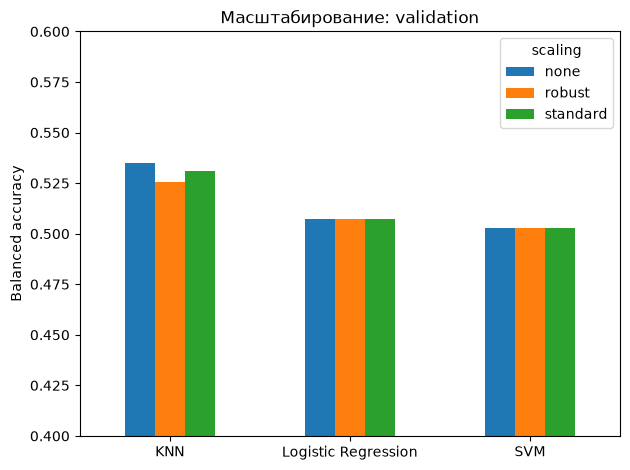

In [11]:
scale_table = pd.DataFrame({
    'KNN': knn_table.groupby('scaling')['balanced_accuracy'].max(),
    'Logistic Regression': lr_table.groupby('scaling')['balanced_accuracy'].max(),
    'SVM': svm_table.groupby('scaling')['balanced_accuracy'].max(),
}).T
display(scale_table)
scale_table.plot.bar(ylim=(0.4, 0.6), ylabel='Balanced accuracy', title='Масштабирование: validation')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Балансировка
У лучшего исходного алгоритма KNN нет `class_weight`: сравним его без балансировки и со SMOTE.
Для дерева дополнительно проверим все три варианта. Параметры оставляем выбранными выше.
SMOTE применяем только к обучению.

In [12]:
knn_smote = ImbPipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=42)),
    ('model', KNeighborsClassifier(n_neighbors=knn_k)),
])
tree_weight = DecisionTreeClassifier(
    max_depth=tree_depth, min_samples_leaf=10, class_weight='balanced', random_state=42,
)
tree_smote = ImbPipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=42)),
    ('model', DecisionTreeClassifier(max_depth=tree_depth, min_samples_leaf=10, random_state=42)),
])

balance_models = [
    ('KNN', knn_smote, knn_scaling, 'SMOTE'),
    ('Decision Tree', tree_weight, 'none', 'class_weight'),
    ('Decision Tree', tree_smote, 'none', 'SMOTE'),
]
for name, model, scaling, balancing in balance_models:
    model.fit(fit_data[scaling], y_fit)
    pred = model.predict(valid_data[scaling])
    validation.append([name, scaling, balancing, accuracy_score(y_valid, pred),
                       balanced_accuracy_score(y_valid, pred)])

validation_table = pd.DataFrame(validation, columns=[
    'algorithm', 'scaling', 'balancing', 'accuracy', 'balanced_accuracy',
])
display(validation_table.sort_values('balanced_accuracy', ascending=False))
chosen = validation_table.sort_values('balanced_accuracy', ascending=False).iloc[0]
print('Выбор до проверки на тесте:', chosen['algorithm'], chosen['scaling'], chosen['balancing'])

,algorithm,scaling,balancing,accuracy,balanced_accuracy
8,Decision Tree,none,class_weight,0.628161,0.590011
7,KNN,none,SMOTE,0.624138,0.582085
9,Decision Tree,none,SMOTE,0.802011,0.553925
0,KNN,none,none,0.839943,0.534899
1,Decision Tree,none,none,0.831897,0.524609
6,Stacking,inside model,none,0.851149,0.509703
2,Logistic Regression,none,none,0.852586,0.507369
4,Random Forest,none,none,0.852299,0.506406
5,AdaBoost,none,none,0.851724,0.502890
3,SVM,standard,none,0.851724,0.502890


Выбор до проверки на тесте: Decision Tree none class_weight


## 12. Подготовка к итоговому тесту
Теперь обучаем обработку на всём 2022 и применяем к 2023. Настройки уже выбраны.
Столбцы теста приводим к столбцам обучения; неизвестные категории получат нули.

In [13]:
X_train = pd.get_dummies(X_train, columns=categorical).astype(float)
X_test = pd.get_dummies(X_test, columns=categorical).astype(float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

train_data = {'none': X_train, 'inside model': X_train}
test_data = {'none': X_test, 'inside model': X_test}
for name, scaler in [('standard', StandardScaler()), ('robust', RobustScaler())]:
    train_data[name] = X_train.copy()
    test_data[name] = X_test.copy()
    train_data[name][numeric] = scaler.fit_transform(X_train[numeric])
    test_data[name][numeric] = scaler.transform(X_test[numeric])

baseline = [0] * len(y_test)
print('Всегда не ушёл: accuracy =', accuracy_score(y_test, baseline))
print('Всегда не ушёл: balanced accuracy =', balanced_accuracy_score(y_test, baseline))

Всегда не ушёл: accuracy = 0.8678279866620674
Всегда не ушёл: balanced accuracy = 0.5


## 13. Итоговая таблица и топ-5 признаков
Для каждой модели явно задаём выбранные настройки, обучаем на 2022 и проверяем на 2023.
У деревьев берём встроенные важности у LR и SVM коэффициенты по модулю, сохраняя знак.
У KNN нет встроенных важностей, а веса стекинга относятся к моделям, а не исходным признакам.

In [14]:
models = [
    ('KNN', with_imputer(KNeighborsClassifier(n_neighbors=knn_k)), knn_scaling, 'none'),
    ('Decision Tree', DecisionTreeClassifier(max_depth=tree_depth, min_samples_leaf=10,
                                           random_state=42), 'none', 'none'),
    ('Logistic Regression', with_imputer(LogisticRegression(C=lr_c, max_iter=3000,
                                               random_state=42)), lr_scaling, 'none'),
    ('SVM', with_imputer(LinearSVC(C=svm_c, dual='auto', max_iter=10000, random_state=42)), svm_scaling, 'none'),
    ('Random Forest', RandomForestClassifier(n_estimators=forest_n, max_depth=10,
                                             min_samples_leaf=5, random_state=42), 'none', 'none'),
    ('AdaBoost', with_imputer(AdaBoostClassifier(n_estimators=ada_n, learning_rate=0.5,
                                     random_state=42)), 'none', 'none'),
    ('Stacking', stacking, 'inside model', 'none'),
] + balance_models

results = []
for name, model, scaling, balancing in models:
    model.fit(train_data[scaling], y_train)
    pred = model.predict(test_data[scaling])
    acc = accuracy_score(y_test, pred)
    bacc = balanced_accuracy_score(y_test, pred)
    top5 = 'Нет встроенных важностей'


    fitted_model = model
    if hasattr(model, 'named_steps'):
        fitted_model = model.named_steps['model']

    if name in ['Decision Tree', 'Random Forest', 'AdaBoost']:
        importance = pd.Series(fitted_model.feature_importances_, index=X_train.columns)
        important = importance.sort_values(ascending=False).head(5)
        top5 = ', '.join(important.index)
        print(name, balancing)
        display(important)
    elif name in ['Logistic Regression', 'SVM']:
        coef = pd.Series(fitted_model.coef_[0], index=X_train.columns)
        important = coef.loc[coef.abs().sort_values(ascending=False).head(5).index]
        top5 = ', '.join(important.index)
        print(name)
        display(important)
    elif name == 'Stacking':
        top5 = 'Веса относятся к базовым моделям'

    results.append([name, scaling, balancing, acc, bacc, top5])

report = pd.DataFrame(results, columns=[
    'algorithm', 'scaling', 'balancing', 'accuracy', 'balanced_accuracy', 'top5',
])
pd.set_option('display.max_colwidth', 200)
display(report)
print('Выбрано по validation:', chosen['algorithm'], chosen['balancing'])

Decision Tree none


experience_age_pedagogic_clean    0.241605
age                               0.172708
experience_age_other_clean        0.110111
n_unique_parallel                 0.091968
n_unique_subjects                 0.090147
dtype: float64

Logistic Regression


main_position_cat_учитель      -0.612818
category_qual_cat_высшая       -0.583170
class_manager                  -0.541413
category_qual_cat_вторая        0.333014
academic_degree_cat_кандидат   -0.319947
dtype: float64

SVM


main_position_cat_учитель    -0.280590
academic_degree_cat_доктор   -0.243339
category_qual_cat_высшая     -0.192484
class_manager                -0.140088
category_qual_cat_первая     -0.125136
dtype: float64

... (6 outputs left out)

Decision Tree SMOTE


class_manager                     0.308904
category_qual_cat_высшая          0.143206
n_unique_parallel                 0.108852
experience_age_pedagogic_clean    0.078016
category_qual_cat_не_найдено      0.069602
dtype: float64

,algorithm,scaling,balancing,accuracy,balanced_accuracy,top5
0,KNN,none,none,0.850696,0.517230,Нет встроенных важностей
1,Decision Tree,none,none,0.847361,0.528583,"experience_age_pedagogic_clean, age, experience_age_other_clean, n_unique_parallel, n_unique_subjects"
2,Logistic Regression,none,none,0.867656,0.505985,"main_position_cat_учитель, category_qual_cat_высшая, class_manager, category_qual_cat_вторая, academic_degree_cat_кандидат"
3,SVM,standard,none,0.868000,0.501943,"main_position_cat_учитель, academic_degree_cat_доктор, category_qual_cat_высшая, class_manager, category_qual_cat_первая"
4,Random Forest,none,none,0.867713,0.502884,"experience_age_pedagogic_clean, age, experience_age_other_clean, class_manager, max_parallel"
5,AdaBoost,none,none,0.867885,0.503905,"experience_age_pedagogic_clean, age, main_position_cat_учитель, class_manager, category_qual_cat_не_найдено"
6,Stacking,inside model,none,0.867311,0.508183,Веса относятся к базовым моделям
7,KNN,none,SMOTE,0.652409,0.570388,Нет встроенных важностей
8,Decision Tree,none,class_weight,0.640163,0.604077,"experience_age_pedagogic_clean, age, experience_age_other_clean, n_unique_subjects, n_unique_parallel"
9,Decision Tree,none,SMOTE,0.813441,0.556237,"class_manager, category_qual_cat_высшая, n_unique_parallel, experience_age_pedagogic_clean, category_qual_cat_не_найдено"


Выбрано по validation: Decision Tree class_weight


## 14. Выводы
- Настройки и способ балансировки выбраны по validation внутри 2022; тест 2023 не участвует в выборе.
- Актуальные accuracy, balanced accuracy и топ-5 признаков находятся в таблице выше. Это разные метрики, их нельзя называть ROC-AUC.
- Сравнение масштабирования дано отдельно на validation; параметры обработки обучаются на train.
- SMOTE применяется только к обучающей части. После one-hot он может создавать дробные категориальные индикаторы: это ограничение учебного опыта, а не используемый в Dash способ подготовки.
- Важность признаков описывает модель, а не доказывает причины ухода. Постоянный ответ «не ушёл» нужен как ориентир accuracy.